**Random Forest Model Configuration and Validation Strategy**

A Random Forest Regression model was developed to predict the age-standardized Thalassemia DALY rate using 4 socioeconomic and healthcare-financing indicators:
- GDP per capita (current US$)
- Out-of-pocket expenditure (% of current health expenditure)
- Current health expenditure per capita (current US$)
- Urban population (% of total population)

The model was configured with 200 trees (n_estimators=200) and a random state of 42 to maintain reproducibility.

A 5-fold GroupKFold cross-validation was also applied, using country as the grouping variable. This made sure that observations from the same country would not appear in both the training and validation sets within a fold. All 11 countries appeared in the validation sets exactly once.

Model performance was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).

**Result**
| Metric | Mean | Standard deviation |
|--------|------|----|
| MAE | 11.456 | 1.022 |
| RMSE | 12.708 | 1.483 |
| R square | 0.469 | 0.107 |

**Interpretaion of model's performance**

The number indicates a moderate  performance when generalizing to countries not included in the corresponding training folds. The relatively small standard deviations across folds suggest some consistency in performance across the validation splits. However, the model's predictive ability remains limited, and the results should be interpreted cautiously given the small number of countries and observations.

These findings suggest that socioeconomic and healthcare-financing indicators contain useful predictive information about cross-country variation in Thalassemia DALY rates, however, they do not fully capture the observed burden.

**Warning: Limitations of country-level prediction**

This study uses country-year observations rather than individual-level patient data, so it cannot be directly interpreted as individual-level associations.

The dataset contains only 110 observations from 11 Southeast Asian countries over the period 2010–2019. This relatively small sample might limit the model's ability to learn complex relationships and generalize to countries with different socioeconomic and healthcare characteristics. Also, the 4 predictors do not capture all potential determinants of Thalassemia burden, such as genetic factors, disease prevalence, screening coverage, treatment access, and healthcare-system capacity.

In addition, the four predictors do not capture all potential determinants of Thalassemia burden, such as genetic factors, disease prevalence, screening coverage, treatment access, and healthcare-system capacity.

And finally, the GroupKFold validation strategy evaluates generalization to previously unseen countries, not forecasting future years. Furthermore, Random Forest feature importance and SHAP values describe model-based predictive contributions rather than causal effects.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path

#define path
DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"
FIGURES_DIR = Path("../figures")
RESULTS_DIR = Path("../results")
#path for output
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

#load dataset
df = pd.read_csv(PROCESSED_DIR / "merged_dataset.csv")
print("\nDataset information:")
df.info()
df.head()

Dataset shape: (110, 9)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   country                        110 non-null    str    
 1   year                           110 non-null    int64  
 2   daly_rate                      110 non-null    float64
 3   daly_lower                     110 non-null    float64
 4   daly_upper                     110 non-null    float64
 5   gdp_per_capita                 110 non-null    float64
 6   oop_expenditure                110 non-null    float64
 7   health_expenditure_per_capita  110 non-null    float64
 8   urban_population               110 non-null    float64
dtypes: float64(7), int64(1), str(1)
memory usage: 7.9 KB


,country,year,daly_rate,daly_lower,daly_upper,gdp_per_capita,oop_expenditure,health_expenditure_per_capita,urban_population
0,Brunei Darussalam,2010,10.127763,7.606276,13.710537,34937.555536,8.261349,795.977661,75.250656
1,Brunei Darussalam,2011,10.322006,7.662837,13.878036,46382.827426,8.471869,864.637878,75.312126
2,Brunei Darussalam,2012,10.728791,8.072679,14.623273,46968.597116,8.851929,869.365540,75.271423
3,Brunei Darussalam,2013,11.204321,8.369203,15.556143,44003.064427,9.407419,835.324524,75.175692
4,Brunei Darussalam,2014,11.727929,8.784243,16.022641,41026.508425,7.334599,785.412109,75.057264


In [ ]:
#check quality
#missing values
print("Missing values:")
print(df.isnull().sum())

#duplicate observations by country-year
print(
    "Duplicate country-year observations:",
    df.duplicated(subset=["country", "year"]).sum()
)

#check countries and years
print("Number of countries:", df["country"].nunique())
print("Number of years:", df["year"].nunique())

Missing values:
country                          0
year                             0
daly_rate                        0
daly_lower                       0
daly_upper                       0
gdp_per_capita                   0
oop_expenditure                  0
health_expenditure_per_capita    0
urban_population                 0
dtype: int64
Duplicate country-year observations: 0
Number of countries: 11
Number of years: 10

Years: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]

Countries: ['Brunei Darussalam', 'Cambodia', 'Indonesia', "Lao People's Democratic Republic", 'Malaysia', 'Myanmar', 'Philippines', 'Singapore', 'Thailand', 'Timor-Leste', 'Viet Nam']


In [ ]:
#define target variable
target = "daly_rate"
y = df[target]
print("Target variable:", target)
print("Target shape:", y.shape)

#define predictor variables
predictors = [
    "gdp_per_capita",
    "oop_expenditure",
    "health_expenditure_per_capita",
    "urban_population"
]
X = df[predictors]
print("\nPredictors:")
print(predictors)
print("Feature matrix shape:", X.shape)
X.head()

#defnie country groups (groups each 10 records of a same country into a group)
groups = df["country"]
print("\nNumber of groups:", groups.nunique())
print("Observations per country:")
print(groups.value_counts().sort_index())

Target variable: daly_rate
Target shape: (110,)
Target summary:
count    110.000000
mean      30.556687
std       19.744177
min        0.915548
25%       11.743511
50%       24.995448
75%       50.059365
max       67.501366
Name: daly_rate, dtype: float64

Predictors:
['gdp_per_capita', 'oop_expenditure', 'health_expenditure_per_capita', 'urban_population']
Feature matrix shape: (110, 4)

Number of groups: 11
Observations per country:
country
Brunei Darussalam                   10
Cambodia                            10
Indonesia                           10
Lao People's Democratic Republic    10
Malaysia                            10
Myanmar                             10
Philippines                         10
Singapore                           10
Thailand                            10
Timor-Leste                         10
Viet Nam                            10
Name: count, dtype: int64


In [9]:
#setup a GroupKFold
from sklearn.model_selection import GroupKFold
group_kfold = GroupKFold(n_splits=5)
print("Number of splits:", group_kfold.get_n_splits())

#check how it divides the data
for fold, (train_idx, val_idx) in enumerate(
    group_kfold.split(X, y, groups=groups),
    start=1
):
    train_countries = set(groups.iloc[train_idx])
    val_countries = set(groups.iloc[val_idx])

    print(f"\nFold {fold}")
    print("Training observations:", len(train_idx))
    print("Validation observations:", len(val_idx))
    print("Training countries:", sorted(train_countries))
    print("Validation countries:", sorted(val_countries))

    assert train_countries.isdisjoint(val_countries) #will make sure there's no country being in both train and val
    #if that happens, then the assert function here will help pop up an error

#check that each country appears in val just once
validation_countries = []
for train_idx, val_idx in group_kfold.split(X, y, groups=groups):
    validation_countries.extend(groups.iloc[val_idx].unique())
validation_counts = pd.Series(validation_countries).value_counts()

print("Validation appearances per country:")
print(validation_counts.sort_index())

assert len(validation_counts) == 11
assert (validation_counts == 1).all()

print("\nAll countries appear in validation exactly once.")


Number of splits: 5

Fold 1
Training observations: 80
Validation observations: 30
Training countries: ['Cambodia', 'Indonesia', "Lao People's Democratic Republic", 'Malaysia', 'Philippines', 'Singapore', 'Thailand', 'Timor-Leste']
Validation countries: ['Brunei Darussalam', 'Myanmar', 'Viet Nam']

Fold 2
Training observations: 90
Validation observations: 20
Training countries: ['Brunei Darussalam', 'Cambodia', 'Indonesia', "Lao People's Democratic Republic", 'Myanmar', 'Philippines', 'Singapore', 'Thailand', 'Viet Nam']
Validation countries: ['Malaysia', 'Timor-Leste']

Fold 3
Training observations: 90
Validation observations: 20
Training countries: ['Brunei Darussalam', 'Cambodia', 'Indonesia', 'Malaysia', 'Myanmar', 'Philippines', 'Singapore', 'Timor-Leste', 'Viet Nam']
Validation countries: ["Lao People's Democratic Republic", 'Thailand']

Fold 4
Training observations: 90
Validation observations: 20
Training countries: ['Brunei Darussalam', 'Cambodia', "Lao People's Democratic Repub

In [10]:
#define reusable evaluation metrics
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}
print("Evaluation metrics:", scoring)


Evaluation metrics: {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}


In [23]:
#training
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)
print("Random Forest model initialized!")

#evaluation
from sklearn.model_selection import cross_validate
rf_cv_results = cross_validate(
    estimator=rf_model,
    X=X,
    y=y,
    groups=groups,
    cv=group_kfold,
    scoring=scoring,
    return_train_score=False
)
rf_cv_df = pd.DataFrame(rf_cv_results)
rf_cv_df

Random Forest model initialized!


,fit_time,score_time,test_MAE,test_RMSE,test_R2
0,0.219660,0.033046,-11.728525,-13.410961,0.380167
1,0.205852,0.043118,-12.409941,-12.951630,0.369839
2,0.251105,0.050063,-11.552144,-14.328918,0.435564
3,0.233293,0.032797,-9.500264,-9.920631,0.661862
4,0.207563,0.030676,-12.091495,-12.930297,0.498882


In [25]:
#validation
rf_summary = {
    "Model": "Random Forest",
    "MAE_mean": -rf_cv_results["test_MAE"].mean(),
    "MAE_std": rf_cv_results["test_MAE"].std(),
    "RMSE_mean": -rf_cv_results["test_RMSE"].mean(),
    "RMSE_std": rf_cv_results["test_RMSE"].std(),
    "R2_mean": rf_cv_results["test_R2"].mean(),
    "R2_std": rf_cv_results["test_R2"].std()
}
rf_summary_df = pd.DataFrame([rf_summary])
rf_summary_df
#save result
rf_cv_df.to_csv(
    RESULTS_DIR / "random_forest_cv_results.csv",
    index=False
)
rf_summary_df.to_csv(
    RESULTS_DIR / "random_forest_summary.csv",
    index=False
)
print("Random Forest evaluation results saved!")

Random Forest evaluation results saved!


In [26]:
#table
rf_performance_table = pd.DataFrame({
    "Evaluation Metric": [
        "MAE",
        "RMSE",
        "R²"
    ],
    "Mean": [
        rf_summary["MAE_mean"],
        rf_summary["RMSE_mean"],
        rf_summary["R2_mean"]
    ],
    "Standard Deviation": [
        rf_summary["MAE_std"],
        rf_summary["RMSE_std"],
        rf_summary["R2_std"]
    ]
})
rf_performance_table["Mean ± SD"] = (
    rf_performance_table["Mean"].map("{:.3f}".format)
    + " ± "
    + rf_performance_table["Standard Deviation"].map("{:.3f}".format)
)
rf_performance_table

,Evaluation Metric,Mean,Standard Deviation,Mean ± SD
0,MAE,11.456474,1.021986,11.456 ± 1.022
1,RMSE,12.708487,1.483221,12.708 ± 1.483
2,R²,0.469263,0.106706,0.469 ± 0.107


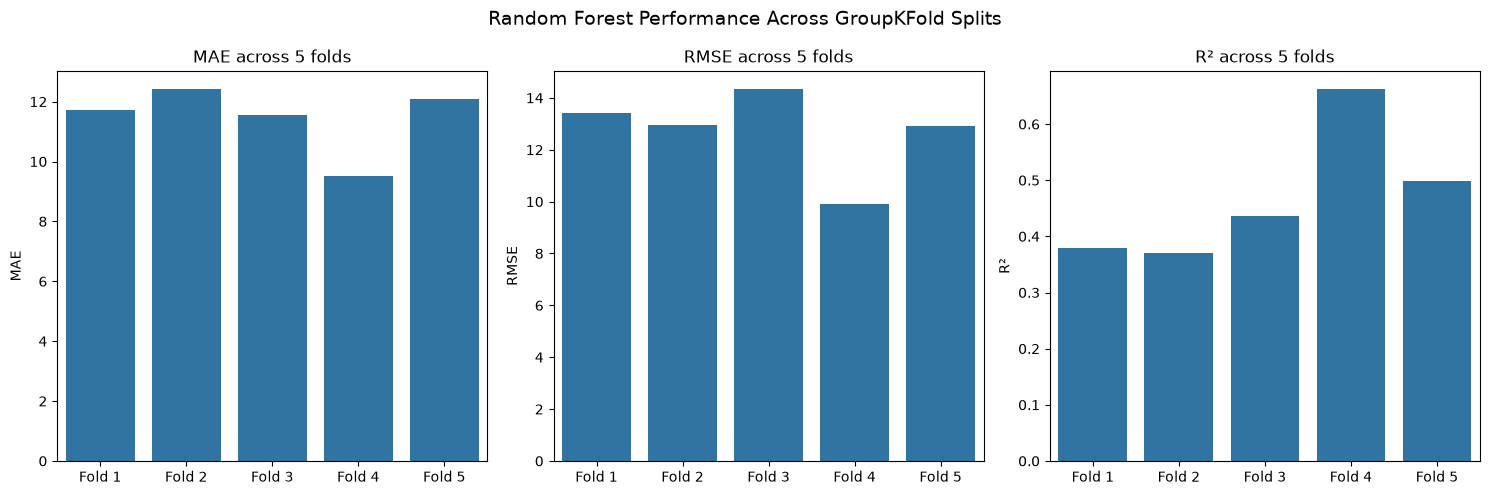

In [27]:
#fold-level metrics to check stability
fold_metrics = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, 6)],
    "MAE": -rf_cv_results["test_MAE"],
    "RMSE": -rf_cv_results["test_RMSE"],
    "R²": rf_cv_results["test_R2"]
})
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = ["MAE", "RMSE", "R²"]
for ax, metric in zip(axes, metrics):
    sns.barplot(
        data=fold_metrics,
        x="Fold",
        y=metric,
        ax=ax
    )
    ax.set_title(f"{metric} across 5 folds")
    ax.set_xlabel("")
    ax.set_ylabel(metric)
plt.suptitle(
    "Random Forest Performance Across GroupKFold Splits",
    fontsize=14
)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "random_forest_fold_performance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

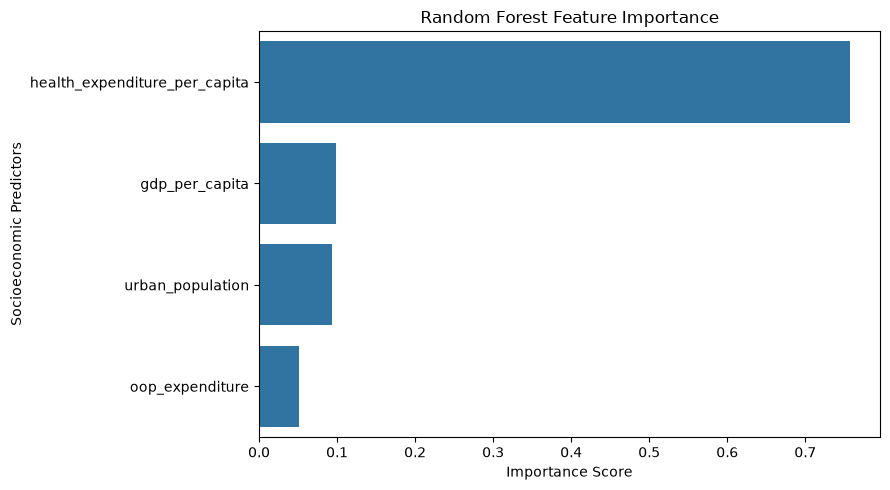

Feature importance results saved!


In [28]:
#feature importance
rf_model.fit(X, y)

feature_importance = pd.DataFrame({
    "Feature": predictors,
    "Importance": rf_model.feature_importances_
})
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)
feature_importance

plt.figure(figsize=(9, 5))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Socioeconomic Predictors")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

feature_importance.to_csv(
    RESULTS_DIR / "random_forest_feature_importance.csv",
    index=False
)
print("Feature importance results saved!")